In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *


from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )

from f2_utils import *
import time_in_each_roi
from skimage import measure


In [3]:
prefix = '/mnt/staging/' # or 
mouse='cm265'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"


h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'

load_root = str(PREPARES / "epochs-csn") + "/"
figure_config_root = str(PREPARES / "config") + "/"


In [4]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))

    if if_return_map ==True:
        return std_map
    else:
        plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
        plt.axis('off')
        plt.colorbar()
def save_model(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_model(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model


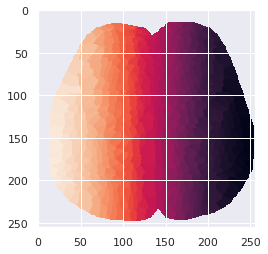

In [5]:
with h5py.File(step_0_root+mouse+'/'+'idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)

# boop

In [6]:
bodyparts = ['RFP','LFP','RHP','LHP']
day6_dict = { 
 'runD':
    "boop_on = 'LHP';stim_frames_raw="+"[1987, 3750, 5565, 7224, 9165, 10908, 12730, 14449, 16410];",
 'runE':
    "boop_on = 'RHP';stim_frames_raw="+"[1870, 3731, 5575, 7320, 9080, 12680, 14550,  16289];",
  'runH':
    "boop_on = 'LFP';stim_frames_raw="+"[1909, 3690, 5516, 7345, 9090,  10870, 12690, 14540, 16288];",
  'runI':
    "boop_on = 'RFP';stim_frames_raw="+"[1988, 3760, 5663, 7360, 9180, 11000, 12782, 14508, 16305];",

            }


In [7]:
file_list=[]
for i_run, run_id in enumerate(day6_dict.keys()):
    exec("file_list.append(glob.glob(step_1_root + mouse+'/6/{}*.mat', recursive=True)[0])".format(run_id))

file_list

['/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm265/6/runD_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm265/6/runE_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm265/6/runH_stim_1.mat',
 '/mnt/staging/users/wx2203/data_submission/steps_data/step_1/cm265/6/runI_stim_1.mat']

In [8]:
import warnings
warnings.filterwarnings('ignore')
###################################################################### M setting

T_PRE = 140
T_POST = 140
T = T_PRE+T_POST
num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1)))) 

M_jrgeco = {key:np.empty((256,256,T,0)) for key in bodyparts}
M_day_label = {key:np.empty((0)) for key in bodyparts}

for i_file,fname in enumerate(file_list): 
    ################################### identity 
    mouse = fname.split('step_1/')[1][0:5]
    day = fname.split(mouse)[1][1:2]
    mouse_day = mouse+'_'+day
    run_name = fname.split('_stim_1')[0].split('/'+day+'/')[1]
    run = run_name
    
    if day=='6':
        string = str(day6_dict[str(run_name)])
        exec(string);print(string[:15])
        
    stim_frames = np.round(np.array(stim_frames_raw)/3,decimals=-1).astype('int')
    
    total_frames = 8000
    start_stop_ind = pd.DataFrame(stim_frames)
    start_stop_ind = start_stop_ind[start_stop_ind[0]<total_frames-T_POST]
    for i in range(len(start_stop_ind)):
        
        cut_range = range(start_stop_ind.iloc[i,0]-T_PRE,start_stop_ind.iloc[i,0]+T_POST)

        with h5py.File(fname, "r") as f_H:
            m = f_H['m']
            C = np.array(f_H['C']['jrgeco'])
            S = np.array(f_H['S']['jrgeco'])[cut_range,:]
            # cut [-60,60] frames slice
            mask = np.array(f_H['mask'])
            # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
            nanidx = np.squeeze(m['nanidx'])==1
            CS = np.dot(S,C).transpose()
            jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
            jrgeco[:] = np.nan
            jrgeco[nanidx==True,:] = CS
            jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

        jrgeco_dsl = jrgeco-np.mean(jrgeco[:,:,:100],axis=2)[:,:,np.newaxis]
        M_jrgeco[boop_on] = np.append(M_jrgeco[boop_on],jrgeco_dsl[:,:,:,np.newaxis],axis=3)
        M_day_label[boop_on] = np.append(M_day_label[boop_on],mouse_day+'_'+run)



boop_on = 'LHP'
boop_on = 'RHP'
boop_on = 'LFP'
boop_on = 'RFP'


In [10]:
sns.set_style("whitegrid", {'axes.grid' : False})
contours = {key:[] for key in bodyparts}
clean_contours = {key:[] for key in bodyparts}
brightest_ind = {key:[] for key in bodyparts}
vmax_dict = {key:[] for key in bodyparts}
t_range_dict = {key:[] for key in bodyparts}
homunculus_rois = {key:[] for key in bodyparts}

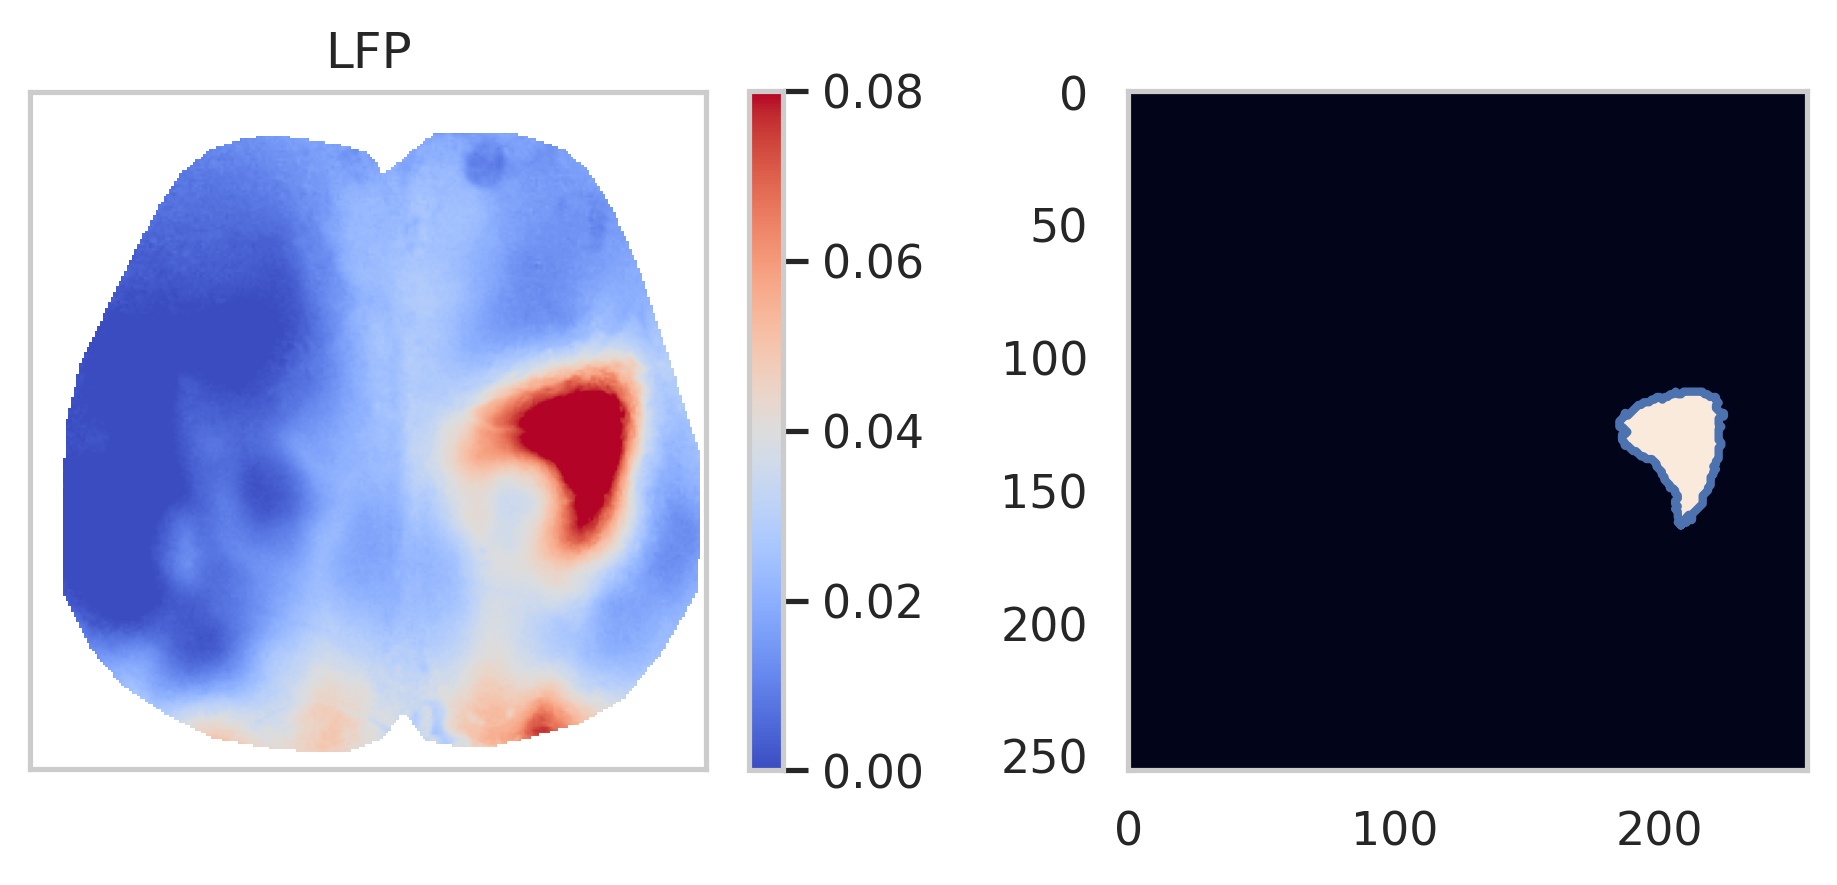

In [28]:
bodypart_name='LFP'
plt.figure(figsize=(8,3),dpi=300)
plt.subplot(121)
t_range_dict[bodypart_name] = range(T_PRE+10,T_PRE+20)

brain_map = np.mean(np.mean(M_jrgeco[bodypart_name],axis=-1)[:,:,t_range_dict[bodypart_name] ],axis=-1)
# brain_map = cv2.warpAffine(brain_map,M[0:2,:],(256,256))

vmax_dict[bodypart_name] = 0.08
plt.imshow(brain_map,vmin=0,vmax=vmax_dict[bodypart_name],cmap='coolwarm')
plt.colorbar()
plt.xticks([]);plt.yticks([]);
plt.title(bodypart_name)
plt.subplot(122)
bw= brain_map>0.08
plt.imshow(bw)
filled_bw = scipy.ndimage.morphology.binary_fill_holes(bw)
contours[bodypart_name] = measure.find_contours(filled_bw, 0.8)
clean_contours[bodypart_name]=[]
for i_contour,contour in enumerate(contours[bodypart_name]):
    # print(len(contour))
    if np.logical_or(len(np.where(np.array(contour[:,0]>230)==True)[0]),len(contour)<20):
        print('place holder')
    else:
        clean_contours[bodypart_name].append(contours[bodypart_name][i_contour])

for contour in clean_contours[bodypart_name]:
    plt.plot(contour[:,1],contour[:,0],linewidth=2)


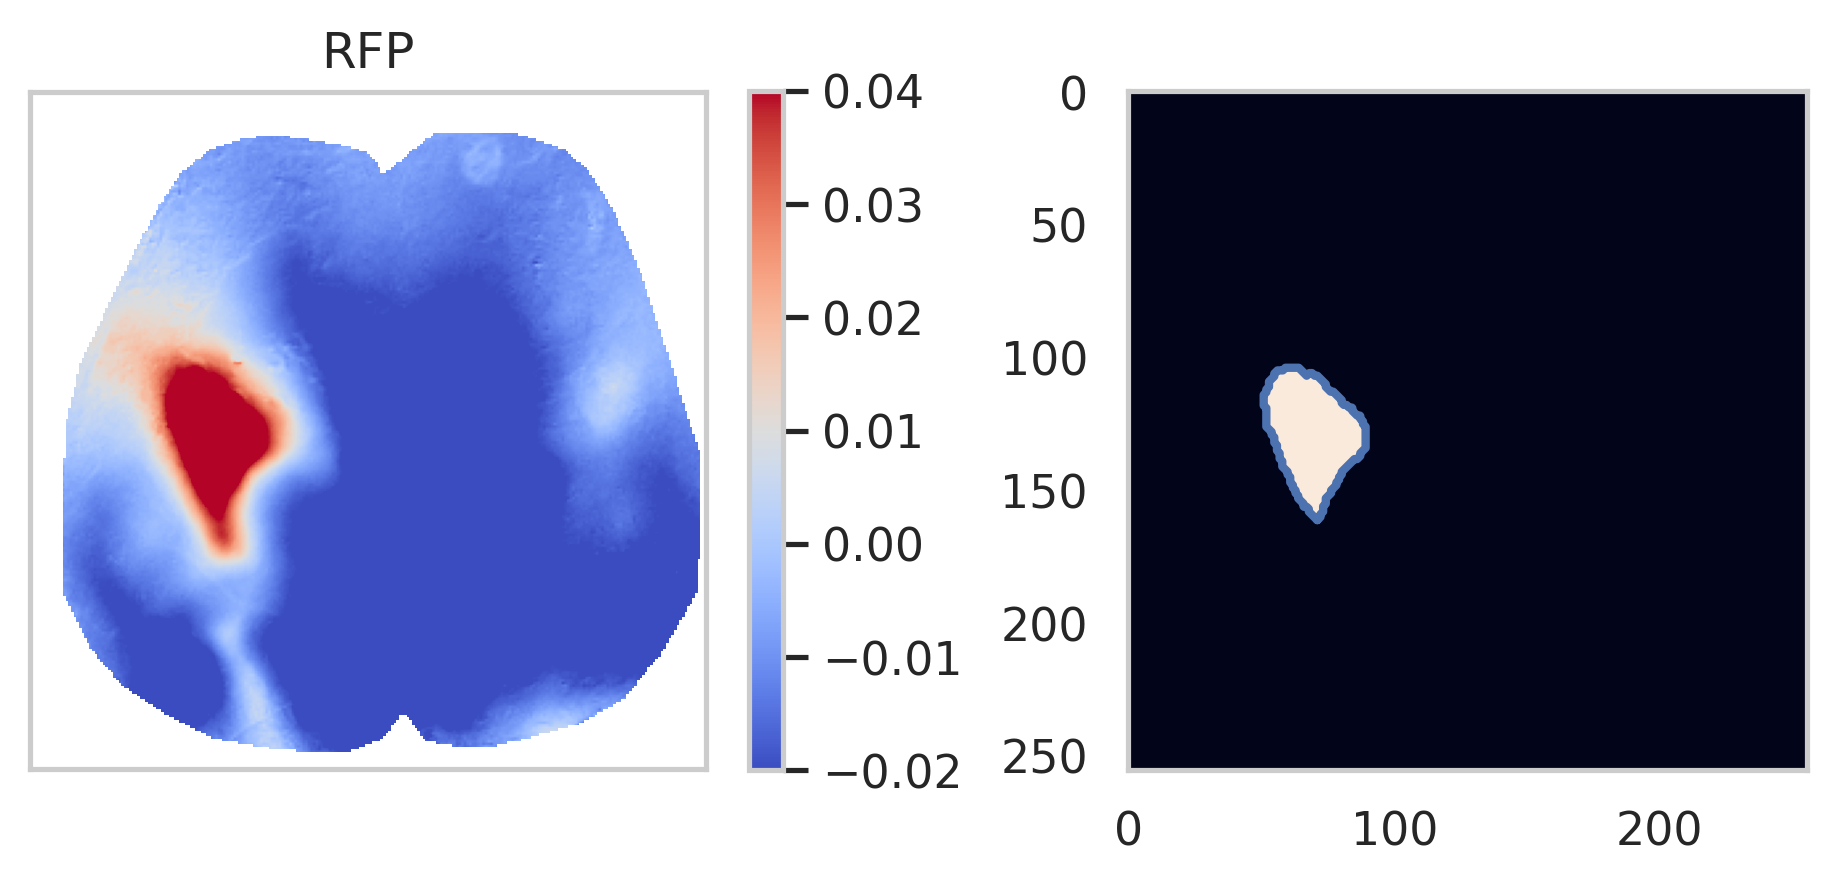

In [29]:
bodypart_name='RFP'
plt.figure(figsize=(8,3),dpi=300)
plt.subplot(121)
t_range_dict[bodypart_name] = range(T_PRE+5,T_PRE+30)
brain_map = np.mean(np.mean(M_jrgeco[bodypart_name],axis=-1)[:,:,t_range_dict[bodypart_name] ],axis=-1)
# brain_map = cv2.warpAffine(brain_map,M[0:2,:],(256,256))

vmax_dict[bodypart_name] = 0.04
plt.imshow(brain_map,vmin=-0.02,vmax=vmax_dict[bodypart_name],cmap='coolwarm')
plt.colorbar()
plt.xticks([]);plt.yticks([]);
plt.title(bodypart_name)
plt.subplot(122)
bw= brain_map>0.04
plt.imshow(bw)
filled_bw = scipy.ndimage.morphology.binary_fill_holes(bw)
contours[bodypart_name] = measure.find_contours(filled_bw, 0.8)
clean_contours[bodypart_name]=[]
for i_contour,contour in enumerate(contours[bodypart_name]):
    # print(len(contour))
    if np.logical_or(len(np.where(np.array(contour[:,0]>230)==True)[0]),len(contour)<20):
        print('place holder')
    else:
        clean_contours[bodypart_name].append(contours[bodypart_name][i_contour])

for contour in clean_contours[bodypart_name]:
    plt.plot(contour[:,1],contour[:,0],linewidth=2)



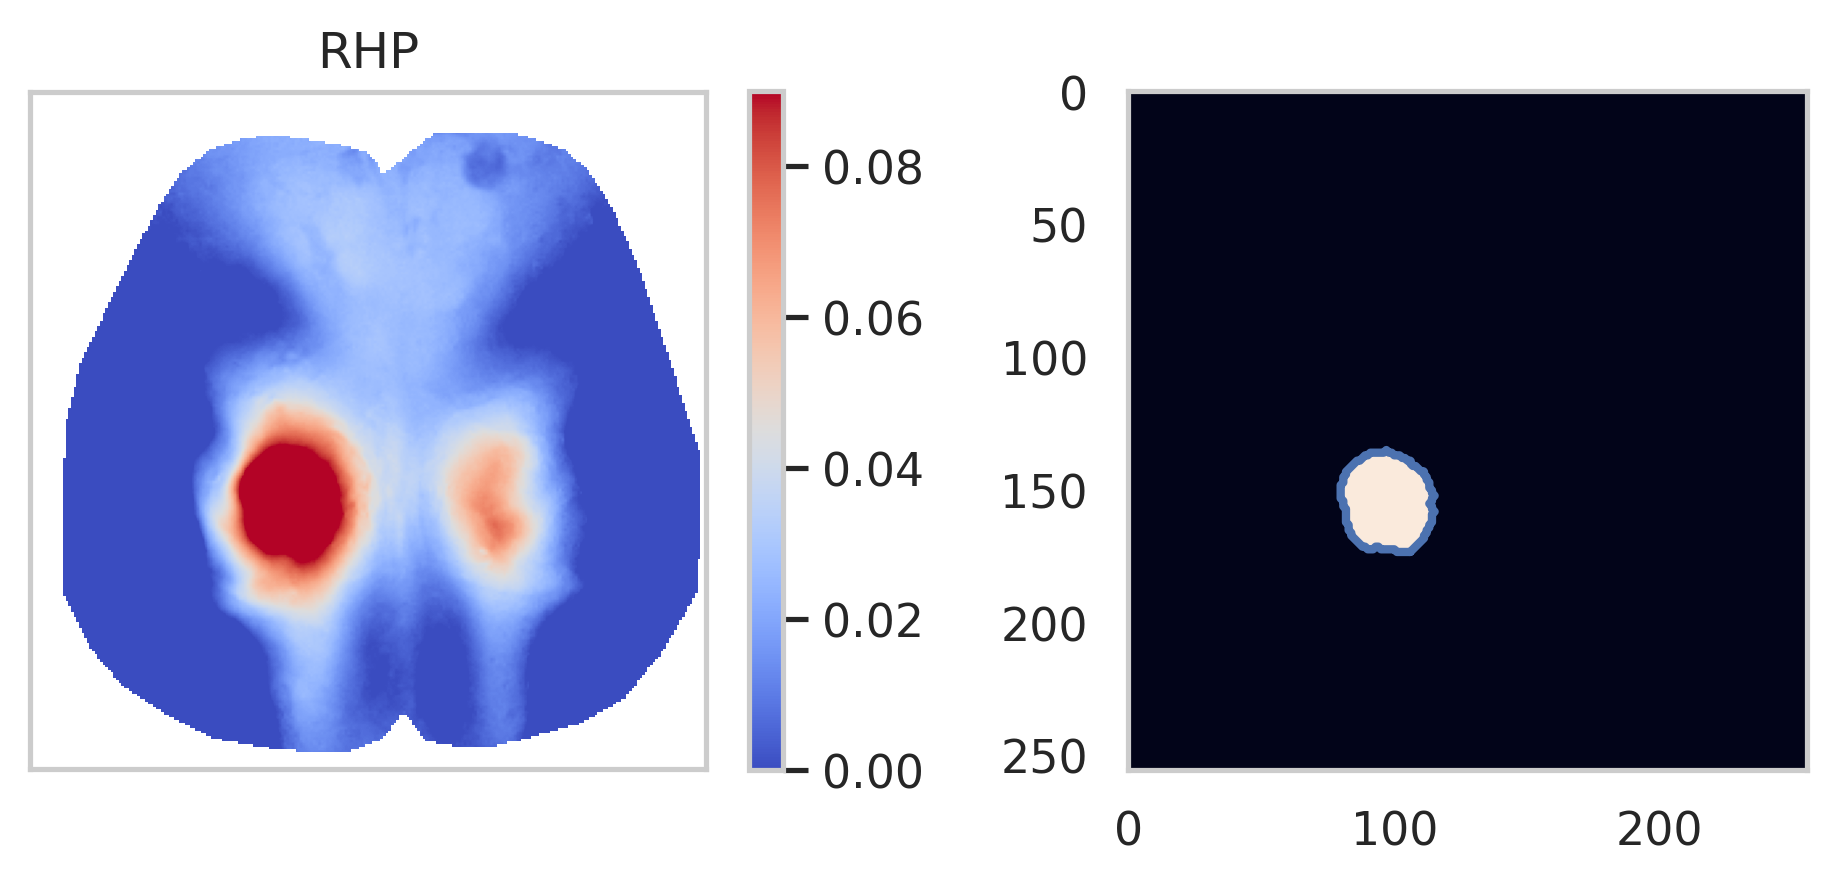

In [30]:
bodypart_name='RHP'
plt.figure(figsize=(8,3),dpi=300)
plt.subplot(121)
t_range_dict[bodypart_name] = range(T_PRE+20,T_PRE+140)

brain_map = np.mean(np.mean(M_jrgeco[bodypart_name],axis=-1)[:,:,t_range_dict[bodypart_name] ],axis=-1)
# brain_map = cv2.warpAffine(brain_map,M[0:2,:],(256,256))


vmax_dict[bodypart_name] = 0.09
plt.imshow(brain_map,vmin=0,vmax=vmax_dict[bodypart_name],cmap='coolwarm')
plt.colorbar()
plt.xticks([]);plt.yticks([]);
plt.title(bodypart_name)
plt.subplot(122)
bw= brain_map>0.1
plt.imshow(bw)
filled_bw = scipy.ndimage.morphology.binary_fill_holes(bw)
contours[bodypart_name] = measure.find_contours(filled_bw, 0.8)

clean_contours[bodypart_name]=[]
for i_contour,contour in enumerate(contours[bodypart_name]):
    # print(len(contour))
    if np.logical_or(len(np.where(np.array(contour[:,0]>230)==True)[0]),len(contour)<20):
        print('place holder')
    else:
        clean_contours[bodypart_name].append(contours[bodypart_name][i_contour])

for contour in clean_contours[bodypart_name]:
    plt.plot(contour[:,1],contour[:,0],linewidth=2)



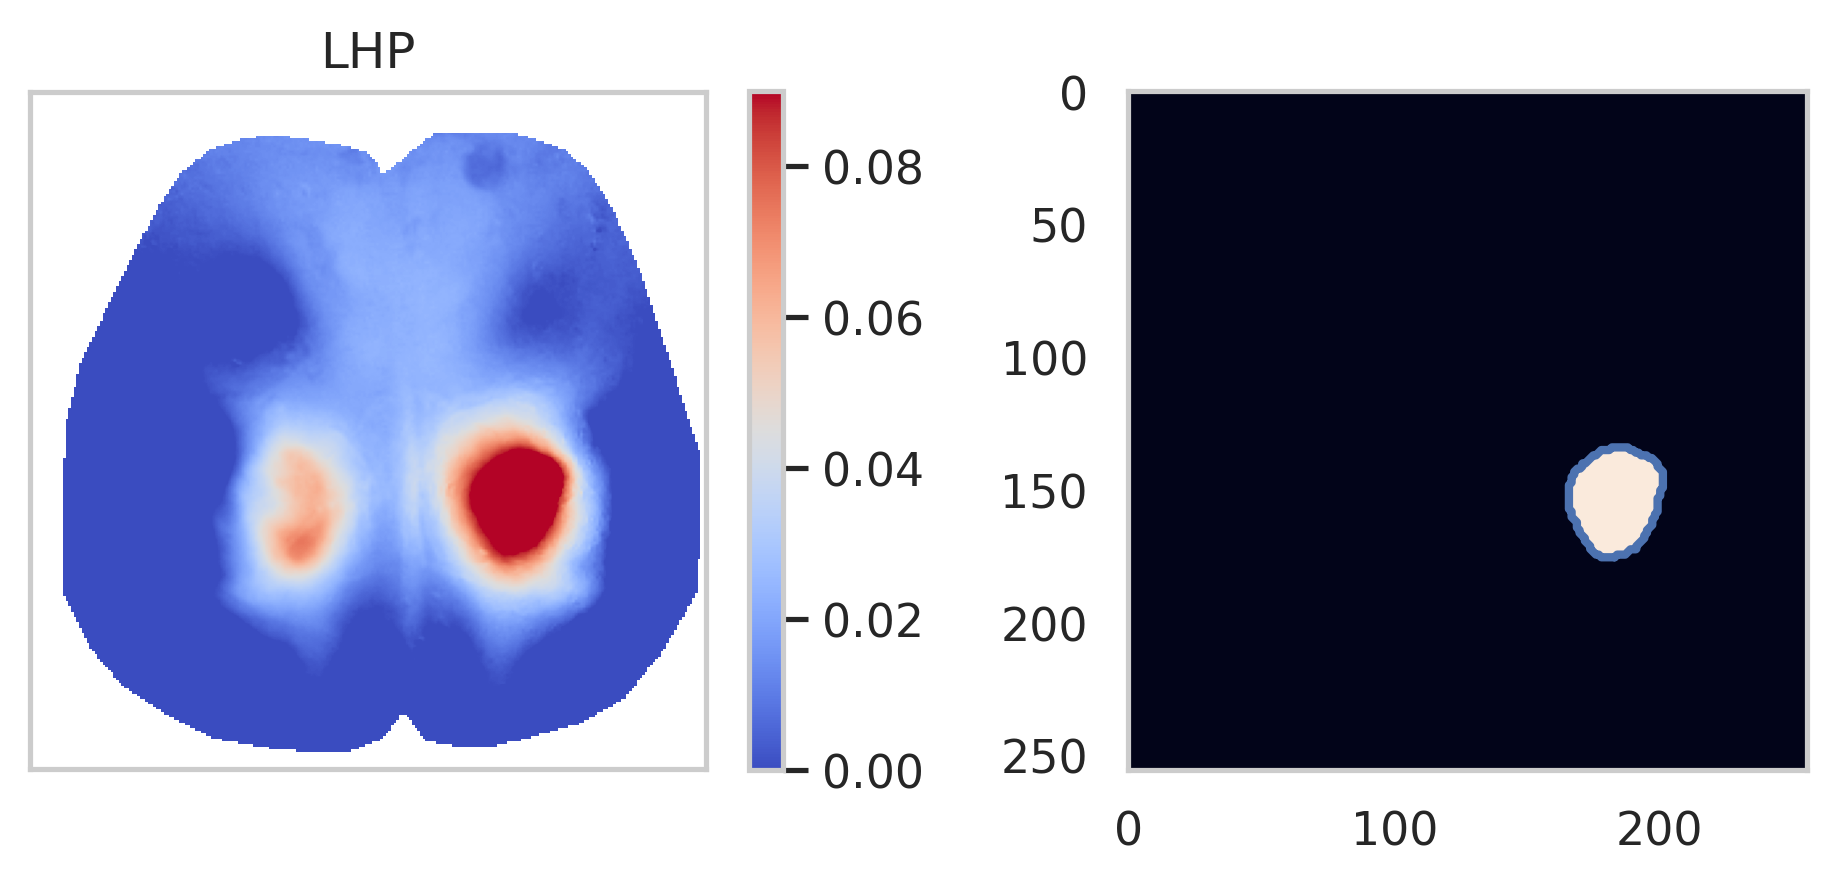

In [31]:
bodypart_name='LHP'
plt.figure(figsize=(8,3),dpi=300)
plt.subplot(121)
t_range_dict[bodypart_name] = range(T_PRE+40,T_PRE+140)

brain_map = np.mean(np.mean(M_jrgeco[bodypart_name],axis=-1)[:,:,t_range_dict[bodypart_name] ],axis=-1)
# brain_map = cv2.warpAffine(brain_map,M[0:2,:],(256,256))

vmax_dict[bodypart_name] = 0.09
plt.imshow(brain_map,vmin=0,vmax=vmax_dict[bodypart_name],cmap='coolwarm')
plt.colorbar()
plt.xticks([]);plt.yticks([]);
plt.title(bodypart_name)
plt.subplot(122)

bw= brain_map>0.085
plt.imshow(bw)
filled_bw = scipy.ndimage.morphology.binary_fill_holes(bw)
contours[bodypart_name] = measure.find_contours(filled_bw, 0.8)


clean_contours[bodypart_name]=[]
for i_contour,contour in enumerate(contours[bodypart_name]):
    # print(len(contour))
    if np.logical_or(len(np.where(np.array(contour[:,0]>230)==True)[0]),len(contour)<20):
        print('place holder')
    else:
        clean_contours[bodypart_name].append(contours[bodypart_name][i_contour])

for contour in clean_contours[bodypart_name]:
    plt.plot(contour[:,1],contour[:,0],linewidth=2)


In [32]:
save_path =  str(FIGURES / "figure5") + "/"
save_model(homunculus_rois,save_path+'homunculus_rois_unregistered_'+mouse)


In [33]:
save_model(clean_contours,save_path+'clean_contours_unregistered_'+mouse)